# 01 · Obtención de datos

Descarga la base de **buques grandes 2024** publicada en el Anexo V ("Flujos de tráfico 2022-2024") de la licitación de la Vía Navegable Troncal, en la página de la Agencia Nacional de Puertos y Navegación.

El archivo se guarda tal cual en `datos/crudo/` y **no se edita a mano**.

## Librerías

Antes de correr, elegir como kernel el Python del entorno `.venv` de esta carpeta. La primera celda muestra qué Python se está usando e instala en él las versiones de `requirements.txt` (si ya están instaladas, no hace nada).

In [257]:
import sys

print(sys.executable)  # debería terminar en .venv\Scripts\python.exe
%pip install -q -r requirements.txt

c:\Users\Damián\Damian - Facultad\Maestria en Economía\python\Damian_Tp_integrador\.venv\Scripts\python.exe
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [258]:
import json
import re
import unicodedata
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from rapidfuzz import fuzz, process, utils

### Parámetros

In [259]:
URL_PAGINA = ("https://www.argentina.gob.ar/economia/agencia-nacional-de-puertos-y-navegacion/" "llamado-licitacion-publica-nacional-e")
TEXTO_LINK = "Buques grandes 2024"  # texto del botón en la página, se puede cambiar a buques chicos u otro año

CARPETA_CRUDO = Path("datos/crudo")  # ruta relativa a la carpeta del proyecto
CARPETA_CRUDO.mkdir(parents=True, exist_ok=True)

### Pido el HTML de la página

In [260]:
respuesta = requests.get(URL_PAGINA, timeout=30)
respuesta.raise_for_status()
print(respuesta.status_code)

200


### Busco el link del archivo dentro del HTML

In [261]:
soup = BeautifulSoup(respuesta.text, "html.parser")
soup.find_all("a")
# en los <a> de la página se encuentran links en el elemento href, y el texto del botón en el elemento <span> dentro del <a>

[<a class="element-invisible element-focusable" href="#main-content">Pasar al contenido principal</a>,
 <a aria-label="Argentina.gob.ar Presidencia de la Nación" class="navbar-brand" href="/" id="navbar-brand">
 <img alt="Argentina.gob.ar" height="50" src="/profiles/argentinagobar/themes/argentinagobar/argentinagobar_theme/logo_argentina-azul.svg" width="254"/>
 </a>,
 <a class="btn btn-mi-argentina btn-login visible-xs bg-miarg-azul" href="https://mi.argentina.gob.ar" title="Ingresar a Mi Argentina">
 <i class="icono-arg-mi-argentina text-white"></i><span class="sr-only">Ir a Mi Argentina</span></a>,
 <a aria-label="Ingresar a Mi Argentina" class="btn hidden-xs p-l-1 btn-login bg-miarg-azul" href="https://mi.argentina.gob.ar/" id="btn-mi-argentina">
 <i class="fa-3x fa icono-arg-mi-argentina-extended text-white p-t-0"><span class="sr-only">Mi Argentina</span></i></a>,
 <a href="/" itemprop="item"><span itemprop="name">Inicio</span></a>,
 <a href="/economia" itemprop="item"><span itemp

In [262]:
link = soup.find("a", string=TEXTO_LINK) # busco el que tiene como nombre el texto_link
assert link is not None, f"No se encontró el link '{TEXTO_LINK}' en la página" # verifico que está

print(link["href"])
# me quedo con el href, pero tiene blank:# que se lo tengo que sacar

url_archivo = link["href"].replace("blank:#", "")

nombre = url_archivo.split("/")[-1] # me quedo con el nombre, que es lo último de la url despues de la /
destino = CARPETA_CRUDO / nombre
print(url_archivo)
print(destino)

blank:#https://www.argentina.gob.ar/sites/default/files/2025/12/2024_buques_grandes_protegido.xlsx
https://www.argentina.gob.ar/sites/default/files/2025/12/2024_buques_grandes_protegido.xlsx
datos\crudo\2024_buques_grandes_protegido.xlsx


## Descargao el archivo solo si no está en disco

La razón por la cual tiene la opción del parámetro "params" es para, mas adelante, importar una base con coordenadas

In [263]:
def descargar_archivo(url, destino, params=None):
    '''
    Descarga el archivo de `url` y lo guarda en `destino`, sin modificarlo.

    Si el archivo ya existe, no lo vuelve a descargar.

    Input:
        url (str): dirección del archivo en la web
        destino (Path): ruta donde guardarlo
        params (dict, opcional): parámetros que se agregan a la URL (?clave=valor&...)
    Output:
        Path: la ruta del archivo en disco
    '''
    if destino.exists():
        print(f'Ya existe, no se descarga de nuevo: {destino}')
        return destino

    respuesta = requests.get(url, params=params, timeout=120)
    respuesta.raise_for_status()
    destino.write_bytes(respuesta.content)  # bytes: se guarda tal cual llega, sea .xlsx o .geojson
    print(f'Descargado el {date.today()}: {destino} ({len(respuesta.content) / 1e6:.1f} MB)')
    return destino

In [264]:
ruta_buques = descargar_archivo(url_archivo, destino)

Ya existe, no se descarga de nuevo: datos\crudo\2024_buques_grandes_protegido.xlsx


## Primer vistazo a la base y chequeo de los tipos de variables

Descripción: La base contiene las salidas de buques grandes de la Vía Navegable Troncal (VNT). Muestra la fecha, hora, zona de salida y zona de destino, medidas y otras características del buque y credenciales, y lo que paga por la tarifa total (total), la de balizamiento (tb) y dragado (td).

Hay un problema, las variables seccion_o y seccion_d las toma como float, cuando en realidad deben ser string, ya que indican de qué sección a cual otra van los barcos y nos va a servir para un futuro merge.

In [265]:
buques = pd.read_excel(ruta_buques)

# Chequeamos que los tipos de datos se
print(buques.shape)
print(buques.dtypes)

buques.head(3)

(18616, 28)
informante               str
fecha         datetime64[us]
hora                     str
seccion_o            float64
origen                   str
dpuerto                  str
seccion_d            float64
destino                  str
hpuerto                  str
matricula                str
buque                    str
mg                       str
trn                  float64
calado               float64
eslora               float64
manga                float64
bandera                  str
caladoreal           float64
agencia                  str
tb                   float64
td                   float64
total                float64
id_mov                 int64
imo                  float64
fact_iva                 str
tipo_b_b                 str
descrip                  str
n_comp                   str
dtype: object


,informante,fecha,hora,seccion_o,origen,dpuerto,seccion_d,destino,hpuerto,matricula,...,agencia,tb,td,total,id_mov,imo,fact_iva,tipo_b_b,descrip,n_comp
0,RECALADA,2024-01-01,03:30:00,0.0,I. MARITIMO (Reca),NaN,1.1,ZONA COMUN,NaN,3E4937,...,FERTIMPORT S.A.,953.84,7717.65,8671.49,2413827,9250165.0,I,TB,TANQUE,FC A 0021-00025380
1,RECALADA,2024-01-01,03:33:00,1.1,ZONA COMUN,NaN,1.2,RIO PARANA GUAZU,NaN,3E4937,...,GOBIERNO,0.00,0.00,0.00,2417109,9250165.0,I,TB,TANQUE,NaN
2,RECALADA,2024-01-01,03:35:00,0.0,I. MARITIMO (Reca),NaN,1.2,DOCK SUD,NaN,LW4200,...,RAIZEN ARGENTINA S.A.U,3988.43,16297.73,20286.16,2413829,9253765.0,N,TB,TANQUE,FC A 0021-00028064


In [266]:
buques[["seccion_o", "seccion_d"]] = buques[["seccion_o", "seccion_d"]].astype(str)
buques['fecha'].dtype

assert pd.api.types.is_datetime64_any_dtype(buques["fecha"]), "fecha no es datetime"
assert buques['fecha'].notna().all(), "hay fechas faltantes"
assert buques['fecha'].dt.day.max() > 12

# 'fecha' es datetime, pero por las dudas...
buques['fecha'] = pd.to_datetime(buques["fecha"], format="%d/%m/%Y")
buques['fecha'].dtype

buques.sort_values(by=['fecha', 'hora'], ascending=True, inplace=True) # ordenamos por fecha y hora por si a caso

## Coordenadas de los puertos (IGN)

La capa **"Puerto"** del Instituto Geográfico Nacional (`ign:puntos_de_puertos_y_muelles_BB005`), con datos del IGN. Se pide al servidor del IGN por en formato GeoJSON y en coordenadas geográficas EPSG:4326.
La capa se guarda tal cual en `datos/geo/`.

In [267]:
CARPETA_GEO = Path('datos/geo')
CARPETA_GEO.mkdir(parents=True, exist_ok=True)

URL_IGN = 'https://wms.ign.gob.ar/geoserver/ows'
PARAMETROS_PUERTOS = {
    'service': 'WFS',                                   # tipo de servicio
    'version': '2.0.0',
    'request': 'GetFeature',                            # pedir los elementos de una capa
    'typeNames': 'ign:puntos_de_puertos_y_muelles_BB005',  # la capa "Puerto"
    'outputFormat': 'application/json',                 # GeoJSON
    'srsName': 'EPSG:4326',                             # latitud y longitud en grados
}

ruta_puertos = descargar_archivo(URL_IGN, CARPETA_GEO / 'ign_puertos.geojson', params=PARAMETROS_PUERTOS)

Ya existe, no se descarga de nuevo: datos\geo\ign_puertos.geojson


Un servidor WFS puede tener un tope de elementos por pedido y cortar la respuesta sin avisar. El GeoJSON trae dos campos para controlarlo: `numberMatched` (cuántos puertos tiene la capa) y `numberReturned` (cuántos vinieron en la respuesta). Tienen que coincidir.

In [268]:
respuesta_ign = json.loads(ruta_puertos.read_text(encoding='utf-8'))
print(respuesta_ign['numberMatched'], respuesta_ign['numberReturned'])

assert respuesta_ign['numberMatched'] == respuesta_ign['numberReturned'], 'la respuesta del IGN vino cortada'

155 155


### Primer vistazo a la capa de puertos

Leemos el GeoJSON como un **GeoDataFrame**. La columna `geometry` guarda el punto de cada puerto y sabe en qué sistema de coordenadas está (`crs`).

In [269]:
puertos = gpd.read_file(ruta_puertos)

print(puertos.shape)
print(puertos.crs)
print(puertos.geom_type.value_counts())

puertos[['fna', 'nam', 'fdc', 'geometry']].head()

(155, 11)
EPSG:4326
Point    155
Name: count, dtype: int64


,fna,nam,fdc,geometry
0,Puerto Reconquista,Reconquista,IGN/Min. de Transporte,POINT (-59.5795 -29.2344)
1,Puerto Cargill S.A. (Ex-Buyatti S.A.I.C.A.),Cargill S.A. (Ex-Buyatti S.A.I.C.A.),IGN/Min. de Transporte,POINT (-58.93599 -27.51266)
2,Puerto Ibicuy,Ibicuy,IGN/Min. de Transporte,POINT (-59.17811 -33.75969)
3,Puerto del Guazú S.A.,del Guazú S.A.,IGN/Min. de Transporte,POINT (-58.88406 -33.90229)
4,Puerto San Antonio Este,San Antonio Este,IGN/Min. de Transporte,POINT (-64.88453 -40.79866)


### Recorte a la zona de la Hidrovía Paraná-Paraguay

Rectángulo aproximado (en grados) que va de Misiones al Río de la Plata. `.cx[lon_min:lon_max, lat_min:lat_max]` se queda con los puntos que caen dentro.

In [270]:
puertos_hpp = puertos.cx[-61.5:-54, -35.5:-25]  # longitud: oeste a este; latitud: sur a norte
print(len(puertos), '->', len(puertos_hpp))

print(sorted(puertos_hpp['fna']))
print(sorted(buques['origen'].dropna().unique()))

155 -> 98
['Puerto ADM Agro S.R.L. (Terminal Arroyo Seco)', 'Puerto ADM Agro S.R.L. (Terminal El Tránsito, Puerto Gral. San Martín)', 'Puerto Acindar S.A.', 'Puerto Aes Argentina Generación S.A.', 'Puerto Akzo Nobel Chemicals S.A.U.', 'Puerto Alvear', 'Puerto Arauco Argentina S.A. (Ex-Faplac S.A.)', 'Puerto Arauco Argentina S.A. (Ex-Resinfor Metanol S.A.)', 'Puerto Arena del Litoral', 'Puerto Asociación de Cooperativas Argentinas A.C.A. Coop. Ltda. (Puerto Vilelas)', 'Puerto Asociación de Cooperativas Argentinas A.C.A. Coop. Ltda. (San Lorenzo)', 'Puerto Asociación de Cooperativas Argentinas A.C.A. Coop. Ltda. (Timbúes)', 'Puerto Axion Energy Argentina S.A. (Ex-Esso Campana)', 'Puerto Axion Energy Argentina S.A. (San Lorenzo)', 'Puerto Bajada Grande', 'Puerto Barranqueras', 'Puerto Buenos Aires', 'Puerto Buey S.A. El Maná', 'Puerto Bunge Argentina S.A. (Bunge Ramallo)', 'Puerto Bunge Argentina S.A. (Ex-La Plata Cereal S.A.)', 'Puerto Campana', 'Puerto Carboclor S.A.', 'Puerto Cargil S.

### Identificar nombres de los puertos de la base IGN con los de la base de buques

Dado que los nombres de los puertos en cada base son diferentes, debemos usar alguna librería como rapidfuzz para matchearlos.
Primero creamos una lista de los 37 lugares de la variable "origen"

In [271]:
puertos_b = buques['origen'].unique().tolist() # creo una lista de los puertos de origen de los buques
puertos_b

type(puertos_b)

list

In [272]:
# este es el intento mas pavote, dado que un simple vistazo al dataframe resultante nos hace dar cuenta de que hay zonas que no son puertos y se matchean con puertos del ign
nombres_ign = puertos_hpp['nam'].tolist()  # se compara contra 'nam' (sin la palabra 'Puerto')

filas = []
for nombre in puertos_b:
    # default_process para pasar a minúsculas y saca puntos y signos antes de comparar. De esto me hizo avivar claude
    match, score, pos = process.extractOne(nombre, nombres_ign, scorer=fuzz.WRatio, processor=utils.default_process)
    filas.append({'origen': nombre, 'nam': puertos_hpp['nam'].iloc[pos], 'fna': puertos_hpp['fna'].iloc[pos], 'score': round(score)})

match_puertos = pd.DataFrame(filas).sort_values('score', ascending=False)
match_puertos

,origen,nam,fna,score
16,RAMALLO,Ramallo,Puerto Ramallo,100
11,BUENOS AIRES,Buenos Aires,Puerto Buenos Aires,100
8,ROSARIO,Rosario,Puerto Rosario,100
6,DOCK SUD,Dock Sud,Puerto Dock Sud,100
5,CAMPANA,Campana,Puerto Campana,100
25,SAN PEDRO,San Pedro,Puerto San Pedro,100
13,SANTA FE,Santa Fe,Puerto Santa Fe,100
26,IBICUY,Ibicuy,Puerto Ibicuy,100
15,VILLA CONSTITUCION,Villa Constitución,Puerto Villa Constitución,94
19,DEL GUAZU S.A.,del Guazú S.A.,Puerto del Guazú S.A.,92


### Match refinado

1. Normalizar con regex antes de comparar: sin tildes, en minúsculas, siglas juntas (`A.C.A.` → `aca`) y sin palabras que no distinguen un puerto de otro (`Puerto`, `Terminal`, `S.A.`, `S.R.L.`, etc.).
2. Separar las zonas no portuarias (ríos, kilómetros, zona común, punto de giro, canal, ingreso marítimo) no son puertos, así que no se buscan en el IGN.
3. Se usa `fuzz.token_set_ratio`, que compara las palabras en común sin importar el orden ni las palabras de más.

Al final, unas pocas correcciones a mano, y la columna `metodo` deja registrado cómo se asignó cada nombre.

In [273]:
# Refinemos un poco el match
def normalizar(nombre):
    '''
    Deja un nombre de puerto listo para comparar.

    Saca tildes, pasa a minúsculas, junta siglas y borra palabras genéricas
    (puerto, terminal) y formas societarias
    
    Input:
        nombre original
    Output:
        nombre normalizado
    '''
    nombre = unicodedata.normalize('NFKD', nombre).encode('ascii', 'ignore').decode()  # 'Zárate' -> 'Zarate'
    nombre = nombre.lower()
    nombre = re.sub(r'\b([a-z])\.(?=[a-z]\.)', r'\1', nombre)  # siglas: 'a.c.a.' -> 'aca.'
    nombre = re.sub(r'\b(puerto|terminal|sa|sau|saic|saica|srl|ltda|coop)\b', ' ', nombre)
    nombre = re.sub(r'[^a-z0-9 ]', ' ', nombre)  # signos y paréntesis los transforma en espacio
    return re.sub(r'\s+', ' ', nombre).strip()  # espacios repetidos los deja con uno solo


# Tests como los de la clase, para ver que la normalización funciona
assert normalizar('A.C.A. TIMBUES') == 'aca timbues'
assert normalizar('Puerto del Guazú S.A.') == 'del guazu'
assert normalizar('Terminal Zárate S.A.') == 'zarate'
assert normalizar('Vicentín S.A.I.C.') == 'vicentin'
assert normalizar('Akzo Nobel Chemicals S.A.U.') == 'akzo nobel chemicals'
assert normalizar('ADM Agro S.R.L. (Terminal Arroyo Seco)') == 'adm agro arroyo seco'

# Hay zonas que no son puertos. eEstas empiezan con río, km, zona, punto de giro, canal, o ingreso/egreso marítimo
PATRON_ZONAS = r'^(RIO|RPP|KM|ZONA|PUNTO|CANAL|[IE]\. MARITIMO)\b'

# Tests
assert re.match(PATRON_ZONAS, 'RPP KM. 460')
assert re.match(PATRON_ZONAS, 'I. MARITIMO (Reca)')
assert re.match(PATRON_ZONAS, 'E. MARITIMO (Reca)')
assert not re.match(PATRON_ZONAS, 'RAMALLO')
assert not re.match(PATRON_ZONAS, 'PUERTO ESCOBAR')

In [274]:
UMBRAL = 80  # por debajo de este puntaje no se acepta el match

nombres_ign = puertos_hpp['nam'].tolist()
nombres_ign_norm = [normalizar(n) for n in nombres_ign]

filas = []
for nombre in buques['origen'].dropna().unique():
    if re.match(PATRON_ZONAS, nombre):
        filas.append({'origen': nombre, 'nam': None, 'score': None, 'metodo': 'zona no portuaria'})
        continue

    resultado = process.extractOne(normalizar(nombre), nombres_ign_norm, scorer=fuzz.token_set_ratio, score_cutoff=UMBRAL)
    if resultado is None:  # ningún puerto del IGN superó el umbral
        filas.append({'origen': nombre, 'nam': None, 'score': None, 'metodo': 'sin match'})
    else:
        _, score, pos = resultado
        filas.append({'origen': nombre, 'nam': nombres_ign[pos], 'score': round(score), 'metodo': 'fuzzy'})

corr = pd.DataFrame(filas)

# Correcciones a mano
CORRECCIONES = {
    'LOUIS DREYFUS': 'L.D.C. Argentina S.A. (Timbúes)',  # el fuzzy se confunde y elige una terminal que no está en la sección 2.0 (Timbúes). De este me hizo dar cuenta la IA
    'COFCO AGRI SUR': 'Cofco Argentina S.A.',            # quedan bajo el umbral por 'agri sur' / 'flotante'
    'COFCO AGRI FLOTANTE': 'Cofco Argentina S.A.',
}
assert set(CORRECCIONES.values()) <= set(nombres_ign), 'hay correcciones que no existen en el IGN'

for origen, nam in CORRECCIONES.items():
    corr.loc[corr['origen'] == origen, ['nam', 'score', 'metodo']] = [nam, None, 'manual']

print(corr['metodo'].value_counts())
corr.sort_values(['metodo', 'score'])

metodo
fuzzy                19
zona no portuaria    11
sin match             4
manual                3
Name: count, dtype: int64


,origen,nam,score,metodo
34,TM. J. DE SAN MARTIN,Termoeléctrica José de San Martín S.A. (Puerto...,84.0,fuzzy
24,CONCEPCION DEL URU,Concepción del Uruguay,90.0,fuzzy
4,SAN LORENZO,Axion Energy Argentina S.A. (San Lorenzo),100.0,fuzzy
5,CAMPANA,Campana,100.0,fuzzy
6,DOCK SUD,Dock Sud,100.0,fuzzy
8,ROSARIO,Rosario,100.0,fuzzy
9,RADA LA PLATA,La Plata,100.0,fuzzy
10,ZARATE,Zárate S.A.,100.0,fuzzy
11,BUENOS AIRES,Buenos Aires,100.0,fuzzy
12,SAN NICOLAS,San Nicolás,100.0,fuzzy


### Merge con el IGN y con la base de buques

Primero la tabla de correspondencia se une con la capa del IGN usando `nam` como id, para traer `fna` y `geometry`. Después esa tabla se une con `buques` usando `origen` como id.

`validate='m:1'` hace que pandas avise si del lado derecho hay ids repetidos (eso duplicaría viajes). Los lugares sin match quedan con `fna` y `geometry` vacíos.

In [275]:
assert puertos_hpp['nam'].is_unique # 'nam' tiene que ser único para usarlo como id

corr_geo = corr.merge(puertos_hpp[['nam', 'fna', 'geometry']], on='nam', how='left', validate='m:1')
corr_geo = gpd.GeoDataFrame(corr_geo, geometry='geometry', crs=puertos_hpp.crs)

assert len(corr_geo) == len(corr) # verifico que no se haya perdido ninguna fila en el merge
corr_geo.tail(3)



,origen,nam,score,metodo,fna,geometry
34,TM. J. DE SAN MARTIN,Termoeléctrica José de San Martín S.A. (Puerto...,84.0,fuzzy,Puerto Termoeléctrica José de San Martín S.A. ...,POINT (-60.78756 -32.57761)
35,PUNTO DE GIRO 1.2,NaN,NaN,zona no portuaria,NaN,None
36,RPP KM. 470,NaN,NaN,zona no portuaria,NaN,None


In [276]:
# agregamos las coordenadas de puertos faltantes que no están en el IGN, pero estan en la base de buques. MAs adelante se agregaran otras quizá.
# a mano
COORDS_FALTANTES = {
    'NUEVA PALMIRA': gpd.points_from_xy([-58.40914], [-33.87070]),
    'TIGRE': gpd.points_from_xy([-58.57187], [-34.41977]),
    'FRAY BENTOS': gpd.points_from_xy([-58.31289], [-33.11488]),
    'AGD': gpd.points_from_xy([-60.75975], [-32.62268]),
}


for origen, coords in COORDS_FALTANTES.items():
    corr_geo.loc[corr_geo['origen'] == origen, ['geometry']] = [coords]

corr_geo[corr_geo['origen'].isin(COORDS_FALTANTES)].tail()

,origen,nam,score,metodo,fna,geometry
7,NUEVA PALMIRA,NaN,NaN,sin match,NaN,POINT (-58.40914 -33.8707)
21,AGD,NaN,NaN,sin match,NaN,POINT (-60.75975 -32.62268)
23,FRAY BENTOS,NaN,NaN,sin match,NaN,POINT (-58.31289 -33.11488)
27,TIGRE,NaN,NaN,sin match,NaN,POINT (-58.57187 -34.41977)


In [277]:
buquesg = buques.merge(corr_geo[['origen', 'fna', 'geometry']], on='origen', how='left', validate='m:1') # este es el merge que agrega las coordenadas a los viajes de buques

print(f"Viajes con coordenadas de origen: {buquesg['fna'].notna().mean()}")

buquesg[['origen', 'fna', 'geometry']].drop_duplicates('origen')

buquesg = gpd.GeoDataFrame(buquesg, geometry='geometry', crs=puertos_hpp.crs)
buquesg[buquesg['seccion_o']=='1.3'].tail()



Viajes con coordenadas de origen: 0.3559840996991835


,informante,fecha,hora,seccion_o,origen,dpuerto,seccion_d,destino,hpuerto,matricula,...,td,total,id_mov,imo,fact_iva,tipo_b_b,descrip,n_comp,fna,geometry
18589,COFCO AGRI SUR,2024-12-31,06:55:00,1.3,COFCO AGRI SUR,NaN,0.0,E. MARITIMO (Reca),NaN,PCOH,...,28940.45,33301.84,6702809,9605176.0,I,NaN,NaN,FC A 0021-00036800,Puerto Cofco Argentina S.A.,POINT (-60.76392 -32.60447)
18593,ROSARIO,2024-12-31,11:50:00,1.3,ROSARIO,NaN,0.0,E. MARITIMO (Reca),NaN,3FOS6,...,28396.50,32906.53,6703170,9595163.0,I,NaN,NaN,FC A 0021-00036799,Puerto Rosario,POINT (-60.62045 -32.96314)
18597,ROSARIO,2024-12-31,14:35:00,1.3,ROSARIO,NaN,1.2,DOCK SUD,NaN,LW3101,...,39611.51,69890.58,6703401,9680035.0,N,NaN,NaN,FC A 0021-00036764,Puerto Rosario,POINT (-60.62045 -32.96314)
18601,SAN LORENZO,2024-12-31,16:09:00,1.3,SAN LORENZO,NaN,0.0,E. MARITIMO (Reca),NaN,9HA4627,...,38327.56,45502.73,6705255,9805659.0,I,NaN,NaN,FC A 0021-00036754,Puerto Axion Energy Argentina S.A. (San Lorenzo),POINT (-60.72922 -32.72565)
18603,SAN LORENZO,2024-12-31,16:46:00,1.3,SAN LORENZO,NaN,0.0,E. MARITIMO (Reca),NaN,9HDZ8,...,37712.34,44265.22,6703575,9324617.0,I,NaN,NaN,FC A 0021-00036751,Puerto Axion Energy Argentina S.A. (San Lorenzo),POINT (-60.72922 -32.72565)


## Límites de las provincias (Georef)

Uso la base de georef que la puedo descargar directo de la web y pesa menos. A la escala que la voy a usar no necesito calidad extrema.
Hay un problema, que pesa demasiado entera, así que lo descargamos en el formato `shp` para el mapa nomás

In [278]:
URL_GEOREF_PROVINCIAS = 'https://apis.datos.gob.ar/georef/api/provincias'

ruta_provincias = descargar_archivo(
    URL_GEOREF_PROVINCIAS, CARPETA_GEO / 'georef_provincias.zip', params={'formato': 'shp'}
)

provincias = gpd.read_file(ruta_provincias, encoding='utf-8')

print(provincias.shape)
print(provincias.crs)
provincias.head()

Ya existe, no se descarga de nuevo: datos\geo\georef_provincias.zip
(24, 5)
EPSG:4326


,id,nombre,centr_lat,centr_lon,geometry
0,02,Ciudad Autónoma de Buenos Aires,-34.6144420654301,-58.4458763250916,"POLYGON ((-58.45535 -34.52776, -58.45404 -34.5..."
1,58,Neuquén,-38.6419828626673,-70.1198972237318,"POLYGON ((-70.39341 -36.15624, -70.39333 -36.1..."
2,74,San Luis,-33.7611035381154,-66.0252312714021,"POLYGON ((-67.05547 -31.85605, -67.05 -31.8574..."
3,82,Santa Fe,-30.7088227091528,-60.9506872769706,"POLYGON ((-61.04639 -27.998, -61.00805 -27.998..."
4,46,La Rioja,-29.6849372775783,-67.1817575814487,"POLYGON ((-68.52136 -27.81792, -68.52148 -27.8..."


## Países vecinos (Natural Earth)

La capa `ign:pais` del IGN trae solo Argentina. Para que se vean Uruguay y los países vecinos se usa el mapa mundial de **Natural Earth** (escala 1:110 millones, dominio público). Es solo un fondo de referencia, poco detallado.

In [279]:
URL_PAISES = 'https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_0_countries.zip' # el mismo de la clase pero con mejor calidad

ruta_paises = descargar_archivo(URL_PAISES, CARPETA_GEO / 'ne_10m_admin_0_countries.zip')
paises = gpd.read_file(ruta_paises)  # se lee el shapefile directo desde el .zip como en clase

print(paises.shape)
print(paises.crs)

Ya existe, no se descarga de nuevo: datos\geo\ne_10m_admin_0_countries.zip
(258, 169)
EPSG:4326


## Ríos de la Hidrovía (IGN)

Fuente: capa **"Corriente de agua"** del IGN. Cada río viene como un **polígono** con la superficie del agua, no como una línea.
Con `CQL_FILTER` el servidor devuelve solo los ríos de la lista.
Faltarían los canales de navegación del Río de la Plata (Punta Indio, Martín García, Emilio Mitre)

In [280]:
RIOS_HPP = ['Río Paraná', 'Río Paraná de las Palmas', 'Río Paraná Guazú', 'Río Paraná Bravo','Río Uruguay', 'Río de la Plata', 'Río Paraguay']
lista_cql = ', '.join(f"'{rio}'" for rio in RIOS_HPP) # creamos una lista para no traer todos los rios de la base. En este me ayudo claude.

PARAMETROS_RIOS = {
    'service': 'WFS',
    'version': '2.0.0',
    'request': 'GetFeature',
    'typeNames': 'ign:areas_de_aguas_continentales_BH140',  # esta es la capa del mapa que nos interesa extraer
    'outputFormat': 'application/json',
    'srsName': 'EPSG:4326',
    'CQL_FILTER': f'fna IN ({lista_cql})',  # filtro solo los ríos de la lista
}

ruta_rios = descargar_archivo(URL_IGN, CARPETA_GEO / 'ign_rios_hpp.geojson', params=PARAMETROS_RIOS)

Ya existe, no se descarga de nuevo: datos\geo\ign_rios_hpp.geojson


In [281]:
rios = gpd.read_file(ruta_rios)

print(rios.crs)
print(rios.geom_type.value_counts())
assert set(rios['fna']) == set(RIOS_HPP), 'falta algún río o vino uno que no se pidió'

print(rios['fna'].value_counts())
rios.head()

EPSG:4326
MultiPolygon    113
Name: count, dtype: int64
fna
Río Paraná                  57
Río Paraguay                38
Río Uruguay                 12
Río Paraná Guazú             2
Río de la Plata              2
Río Paraná de las Palmas     1
Río Paraná Bravo             1
Name: count, dtype: int64


,id,gid,entidad,objeto,fna,gna,nam,hyp,fdc,sag,geometry
0,areas_de_aguas_continentales_BH140.65993,65993,1,Corriente de agua,Río Paraná,Río,Paraná,1,NaN,IGN,"MULTIPOLYGON (((-59.97874 -33.4639, -59.97856 ..."
1,areas_de_aguas_continentales_BH140.65994,65994,1,Corriente de agua,Río Paraná,Río,Paraná,1,NaN,IGN,"MULTIPOLYGON (((-59.68829 -30.39508, -59.69707..."
2,areas_de_aguas_continentales_BH140.65995,65995,1,Corriente de agua,Río Paraná,Río,Paraná,1,NaN,IGN,"MULTIPOLYGON (((-60.50689 -31.69881, -60.49797..."
3,areas_de_aguas_continentales_BH140.65996,65996,1,Corriente de agua,Río Paraná,Río,Paraná,1,NaN,IGN,"MULTIPOLYGON (((-60.65176 -31.79217, -60.65177..."
4,areas_de_aguas_continentales_BH140.66000,66000,1,Corriente de agua,Río Paraná Guazú,Río,Paraná Guazú,1,NaN,IGN,"MULTIPOLYGON (((-59.17013 -33.80387, -59.16988..."


### Control visual: los puertos del IGN sobre el mapa

Un mapa rápido para comprobar que los puntos caen donde deberían (sobre las costas y los ríos). Las dos capas están en EPSG:4326, así que se pueden dibujar juntas sin reproyectar. La capa de Tierra del Fuego incluye el sector antártico, así que se recortan los ejes al territorio continental.

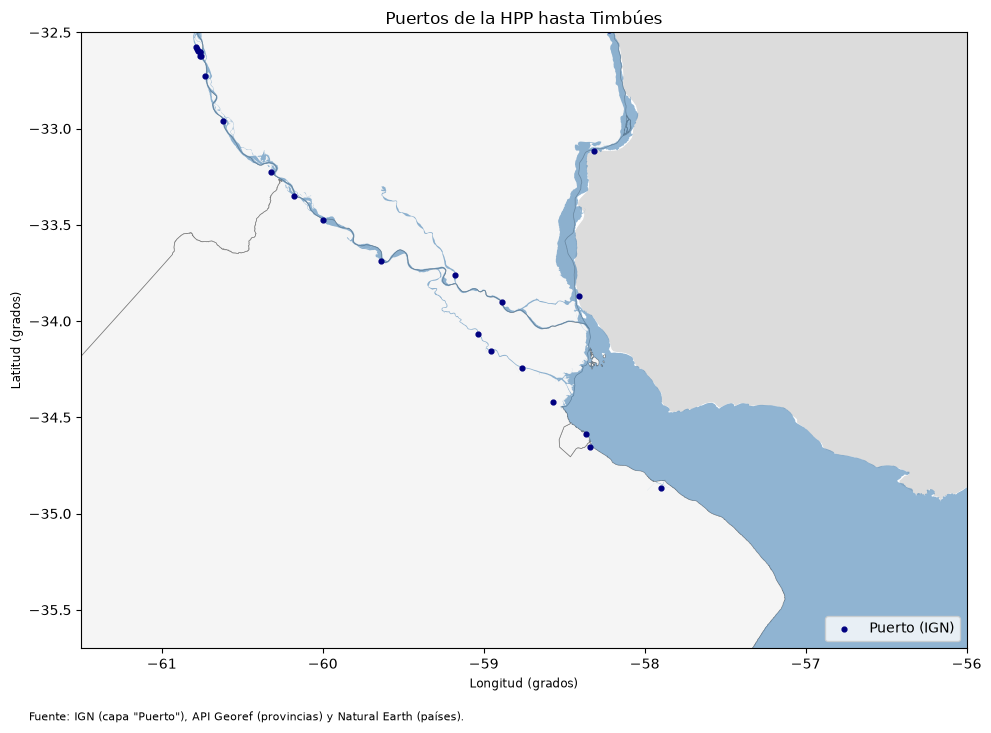

In [282]:
fig, ax = plt.subplots(figsize=(12, 8))
paises.plot(ax=ax, color='gainsboro', edgecolor='white', linewidth=0.8) # muestro paises vecinos en baja calidad (por ahora)
provincias.plot(ax=ax, color='whitesmoke', edgecolor='grey', linewidth=0.5) # delimitaciones de provicias
rios.plot(ax=ax, color='steelblue', alpha=0.6) # Los ríos de la lista
corr_geo.plot(ax=ax, color='navy', markersize=12, label='Puerto (IGN)') # los puertos de la base buques con coords de la IGN

ax.set_xlim(-61.5, -56)  # Aca recorto solo la zona de Argentina y Uruguay
ax.set_ylim(-35.7, -32.5)
ax.set_title('Puertos de la HPP hasta Timbúes')
ax.set_xlabel('Longitud (grados)')
ax.set_ylabel('Latitud (grados)')
ax.legend(loc='lower right')
fig.text(0.1, 0.02, 'Fuente: IGN (capa "Puerto"), API Georef (provincias) y Natural Earth (países).', fontsize=8)

plt.show()